## PRCP-1003 – Customer Transaction Prediction

# 1. Introduction

Banks generate huge volumes of customer data every day, but most of it stays unused simply because no one has the time to look through it manually. One thing banks are especially interested in is predicting customer behaviour — specifically, whether a customer is going to make a transaction or not. If a bank can predict this in advance, it becomes much easier to plan resources, target the right customers with the right offers, and understand overall customer activity patterns.

This project deals with exactly this kind of problem. We are given anonymized banking data where each row represents a customer, and our job is to predict whether that customer will make a transaction in the future, based purely on the numerical patterns present in their data. Since the actual meaning of each feature has been hidden (for privacy/business reasons), this becomes a good exercise in applying machine learning techniques without depending on domain assumptions — the model has to learn purely from the statistical patterns in the numbers.

# 2. Problem Statement

We are given a dataset with 200 anonymized numerical features for a large number of bank customers, along with a target column that tells us whether that customer made a transaction (1) or not (0).

The task has two parts:

Task 1: Analyze this dataset thoroughly and prepare a proper data analysis report.
Task 2: Build a machine learning model that can look at a new customer's data and predict whether they are likely to make a transaction.

Since we don't know what the 200 features actually represent, we cannot use business logic or domain knowledge to guide our analysis — everything has to be based on data patterns, statistics, and model performance.

# 3. Objectives
Understand the structure and quality of the given dataset (size, data types, missing values, duplicates).
Study the distribution of the target variable and check for class imbalance, since this affects how we train and evaluate our models later.
Explore the anonymized features statistically (distributions, spread, correlations) without assigning them any business meaning.
Preprocess the data appropriately so it's ready for machine learning, while being careful not to leak information from outside the training set.
Build and compare multiple classification models (Logistic Regression, Decision Tree, Random Forest, XGBoost/Gradient Boosting, and one more suitable model) using metrics that make sense for an imbalanced target.
Select and justify the best-performing model for production use, and document the challenges faced along the way.

# 4. Dataset Description

The dataset belongs to the banking domain and is provided in anonymized form — meaning the original feature names have been removed/masked, and we are not told what any individual feature represents.

Based on the project statement, the dataset contains:

ID_code – a unique identifier for each customer record.
200 anonymized numerical features (referred to generically, e.g. var_0 to var_199) – these are the input variables used for prediction. Since they are anonymized, we treat them purely as numerical signals and do not assume they represent things like income, age, or balance.
target – the label we are trying to predict:
0 → the customer will not make a transaction
1 → the customer will make a transaction

## 5. Importing Libraries

In [3]:
# Core data handling
import os
import zipfile
import urllib.request
import numpy as np
import pandas as pd

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_style("whitegrid")

# Machine learning - preprocessing & splitting
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import StandardScaler

# Machine learning - models
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

# Machine learning - evaluation
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, confusion_matrix, classification_report
)

# Reproducibility
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Display settings (helps when previewing 200 columns)
pd.set_option("display.max_columns", 50)

print("Libraries imported successfully.")

Libraries imported successfully.


## 6. Loading the Dataset

In [4]:

# ---- 6a. Download the dataset zip ----
DATA_URL = "https://d3ilbtxij3aepc.cloudfront.net/projects/CDS-Capstone-Projects/PRCP-1003-CustTransPred.zip"
ZIP_PATH = "/content/PRCP-1003-CustTransPred.zip"
EXTRACT_DIR = "/content/PRCP-1003-CustTransPred"

if not os.path.exists(ZIP_PATH):
    print("Downloading dataset...")
    urllib.request.urlretrieve(DATA_URL, ZIP_PATH)
    print("Download complete.")
else:
    print("Zip already exists, skipping download.")

# ---- 6b. Extract the zip ----
os.makedirs(EXTRACT_DIR, exist_ok=True)
with zipfile.ZipFile(ZIP_PATH, "r") as zf:
    zf.extractall(EXTRACT_DIR)

# ---- 6c. Find all CSV files inside (handles nested folders too) ----
csv_files = []
for root, dirs, files in os.walk(EXTRACT_DIR):
    for f in files:
        if f.lower().endswith(".csv"):
            csv_files.append(os.path.join(root, f))

print("CSV files found:")
for f in csv_files:
    print(" -", f)

Zip already exists, skipping download.
CSV files found:
 - /content/PRCP-1003-CustTransPred/Data/train(1).csv


In [5]:
# ============================================
#  6. (continued): Loading the dataset into pandas
# ============================================

TRAIN_PATH = "/content/PRCP-1003-CustTransPred/Data/train(1).csv"

df = pd.read_csv(TRAIN_PATH)

print("Shape of the dataset:", df.shape)
df.head()

Shape of the dataset: (200000, 202)


,ID_code,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,var_7,var_8,var_9,var_10,var_11,var_12,var_13,var_14,var_15,var_16,var_17,var_18,var_19,var_20,var_21,var_22,...,var_175,var_176,var_177,var_178,var_179,var_180,var_181,var_182,var_183,var_184,var_185,var_186,var_187,var_188,var_189,var_190,var_191,var_192,var_193,var_194,var_195,var_196,var_197,var_198,var_199
0,train_0,0,8.9255,-6.7863,11.9081,5.0930,11.4607,-9.2834,5.1187,18.6266,-4.9200,5.7470,2.9252,3.1821,14.0137,0.5745,8.7989,14.5691,5.7487,-7.2393,4.2840,30.7133,10.5350,16.2191,2.5791,...,7.7423,-10.1245,13.7241,-3.5189,1.7202,-8.4051,9.0164,3.0657,14.3691,25.8398,5.8764,11.8411,-19.7159,17.5743,0.5857,4.4354,3.9642,3.1364,1.6910,18.5227,-2.3978,7.8784,8.5635,12.7803,-1.0914
1,train_1,0,11.5006,-4.1473,13.8588,5.3890,12.3622,7.0433,5.6208,16.5338,3.1468,8.0851,-0.4032,8.0585,14.0239,8.4135,5.4345,13.7003,13.8275,-15.5849,7.8000,28.5708,3.4287,2.7407,8.5524,...,10.4968,-7.2352,16.5721,-7.3477,11.0752,-5.5937,9.4878,-14.9100,9.4245,22.5441,-4.8622,7.6543,-15.9319,13.3175,-0.3566,7.6421,7.7214,2.5837,10.9516,15.4305,2.0339,8.1267,8.7889,18.3560,1.9518
2,train_2,0,8.6093,-2.7457,12.0805,7.8928,10.5825,-9.0837,6.9427,14.6155,-4.9193,5.9525,-0.3249,-11.2648,14.1929,7.3124,7.5244,14.6472,7.6782,-1.7395,4.7011,20.4775,17.7559,18.1377,1.2145,...,10.9202,-0.3104,8.8438,-9.7009,2.4013,-4.2935,9.3908,-13.2648,3.1545,23.0866,-5.3000,5.3745,-6.2660,10.1934,-0.8417,2.9057,9.7905,1.6704,1.6858,21.6042,3.1417,-6.5213,8.2675,14.7222,0.3965
3,train_3,0,11.0604,-2.1518,8.9522,7.1957,12.5846,-1.8361,5.8428,14.9250,-5.8609,8.2450,2.3061,2.8102,13.8463,11.9704,6.4569,14.8372,10.7430,-0.4299,15.9426,13.7257,20.3010,12.5579,6.8202,...,8.1013,11.8771,13.9552,-10.4701,5.6961,-3.7546,8.4117,1.8986,7.2601,-0.4639,-0.0498,7.9336,-12.8279,12.4124,1.8489,4.4666,4.7433,0.7178,1.4214,23.0347,-1.2706,-2.9275,10.2922,17.9697,-8.9996
4,train_4,0,9.8369,-1.4834,12.8746,6.6375,12.2772,2.4486,5.9405,19.2514,6.2654,7.6784,-9.4458,-12.1419,13.8481,7.8895,7.7894,15.0553,8.4871,-3.0680,6.5263,11.3152,21.4246,18.9608,10.1102,...,16.3309,-3.3456,13.5261,1.7189,5.1743,-7.6938,9.7685,4.8910,12.2198,11.8503,-7.8931,6.4209,5.9270,16.0201,-0.2829,-1.4905,9.5214,-0.1508,9.1942,13.2876,-1.5121,3.9267,9.5031,17.9974,-8.8104


## 7. Basic Data Understanding

In [6]:
# ---- 7a. Data types ----
print("Data types summary:")
print(df.dtypes.value_counts())
print()

# ---- 7b. Missing values ----
missing_counts = df.isnull().sum()
total_missing = missing_counts.sum()
print(f"Total missing values in the dataset: {total_missing}")
if total_missing > 0:
    print("\nColumns with missing values:")
    print(missing_counts[missing_counts > 0])
print()

# ---- 7c. Duplicate rows ----
duplicate_rows = df.duplicated().sum()
print(f"Number of fully duplicate rows: {duplicate_rows}")
print()

# ---- 7d. Uniqueness of ID_code ----
unique_ids = df["ID_code"].nunique()
print(f"Unique ID_code values: {unique_ids} out of {len(df)} rows")
print()

# ---- 7e. Quick statistical summary of a few feature columns ----
print("Statistical summary (first 5 feature columns):")
df[["var_0", "var_1", "var_2", "var_3", "var_4"]].describe()

Data types summary:
float64    200
object       1
int64        1
Name: count, dtype: int64

Total missing values in the dataset: 0

Number of fully duplicate rows: 0

Unique ID_code values: 200000 out of 200000 rows

Statistical summary (first 5 feature columns):


,var_0,var_1,var_2,var_3,var_4
count,200000.000000,200000.000000,200000.000000,200000.000000,200000.000000
mean,10.679914,-1.627622,10.715192,6.796529,11.078333
std,3.040051,4.050044,2.640894,2.043319,1.623150
min,0.408400,-15.043400,2.117100,-0.040200,5.074800
25%,8.453850,-4.740025,8.722475,5.254075,9.883175
50%,10.524750,-1.608050,10.580000,6.825000,11.108250
75%,12.758200,1.358625,12.516700,8.324100,12.261125
max,20.315000,10.376800,19.353000,13.188300,16.671400


## 8. Data Preprocessing

In [7]:
# ---- 8a. Separate identifier, features, and target ----
id_codes = df["ID_code"]
X = df.drop(columns=["ID_code", "target"])
y = df["target"]

print("Features shape (X):", X.shape)
print("Target shape (y):", y.shape)
print()

# ---- 8b. Confirm no leakage-prone columns remain in X ----
print("Columns in X (should be only var_0 ... var_199):")
print(X.columns[:5].tolist(), "...", X.columns[-5:].tolist())
print()

# ---- 8c. Sanity check: target values ----
print("Unique target values:", y.unique())

Features shape (X): (200000, 200)
Target shape (y): (200000,)

Columns in X (should be only var_0 ... var_199):
['var_0', 'var_1', 'var_2', 'var_3', 'var_4'] ... ['var_195', 'var_196', 'var_197', 'var_198', 'var_199']

Unique target values: [0 1]


## 9. Target Variable Analysis

Target class counts:
target
0    179902
1     20098
Name: count, dtype: int64

Target class percentages:
target
0    89.95
1    10.05
Name: proportion, dtype: float64


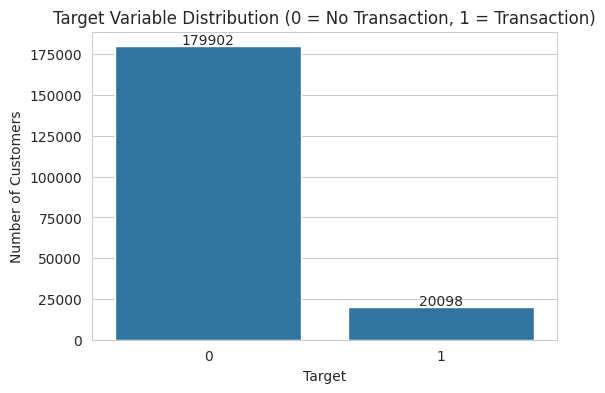

In [8]:

# ---- 9a. Class counts and percentages ----
target_counts = y.value_counts()
target_percent = y.value_counts(normalize=True) * 100

print("Target class counts:")
print(target_counts)
print()
print("Target class percentages:")
print(target_percent.round(2))

# ---- 9b. Visualize the imbalance ----
plt.figure(figsize=(6, 4))
sns.countplot(x=y)
plt.title("Target Variable Distribution (0 = No Transaction, 1 = Transaction)")
plt.xlabel("Target")
plt.ylabel("Number of Customers")
for i, count in enumerate(target_counts.sort_index()):
    plt.text(i, count + 1000, str(count), ha="center")
plt.show()

## 10. Feature Analysis

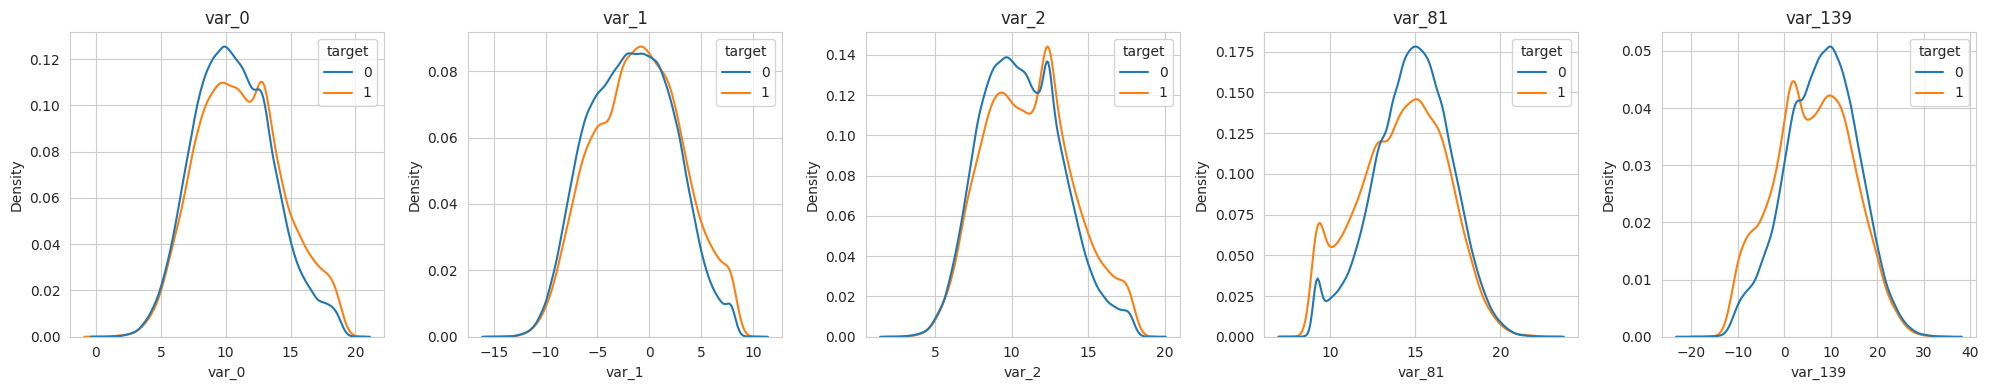

Top 10 features most NEGATIVELY correlated with target:
var_81    -0.080917
var_139   -0.074080
var_12    -0.069489
var_146   -0.063644
var_76    -0.061917
var_174   -0.061669
var_21    -0.058483
var_166   -0.057773
var_80    -0.057609
var_165   -0.055734
dtype: float64

Top 10 features most POSITIVELY correlated with target:
var_0      0.052390
var_133    0.054548
var_2      0.055870
var_190    0.055973
var_99     0.058367
var_22     0.060558
var_26     0.062422
var_53     0.063399
var_110    0.064275
var_6      0.066731
dtype: float64


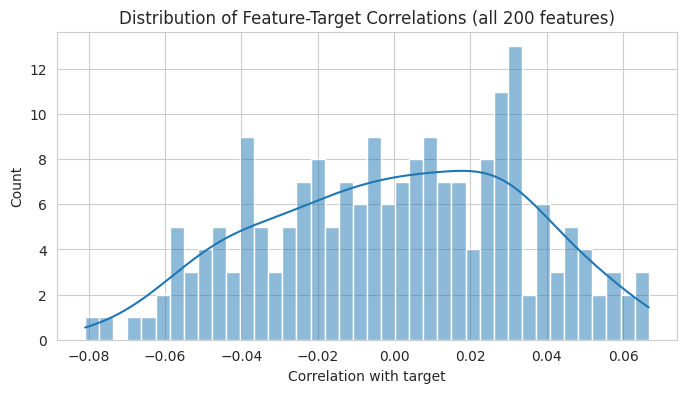

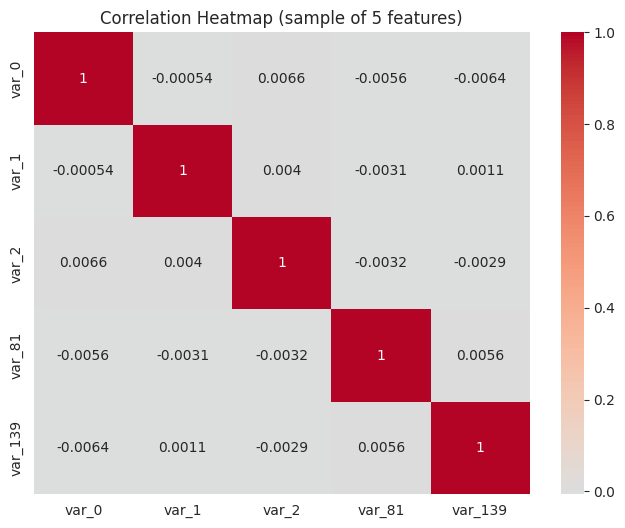

In [9]:

# ---- 10a. Distribution of a few sample features, split by target ----
sample_features = ["var_0", "var_1", "var_2", "var_81", "var_139"]  # a small illustrative sample

fig, axes = plt.subplots(1, len(sample_features), figsize=(20, 4))
for i, col in enumerate(sample_features):
    sns.kdeplot(data=df, x=col, hue="target", ax=axes[i], common_norm=False)
    axes[i].set_title(col)
plt.tight_layout()
plt.show()

# ---- 10b. Correlation of each feature with the target ----
correlations = X.corrwith(y).sort_values()

print("Top 10 features most NEGATIVELY correlated with target:")
print(correlations.head(10))
print()
print("Top 10 features most POSITIVELY correlated with target:")
print(correlations.tail(10))

# ---- 10c. Distribution of these correlation values across all 200 features ----
plt.figure(figsize=(8, 4))
sns.histplot(correlations, bins=40, kde=True)
plt.title("Distribution of Feature-Target Correlations (all 200 features)")
plt.xlabel("Correlation with target")
plt.show()

# ---- 10d. Check for multicollinearity among a sample of features ----
plt.figure(figsize=(8, 6))
sns.heatmap(X[sample_features].corr(), annot=True, cmap="coolwarm", center=0)
plt.title("Correlation Heatmap (sample of 5 features)")
plt.show()

## 11. Train-Test Split

In [10]:

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# ---- 11a. First split off the Test set (15%) ----
X_temp, X_test, y_temp, y_test = train_test_split(
    X, y,
    test_size=0.15,
    stratify=y,
    random_state=RANDOM_STATE
)

# ---- 11b. Split the remainder into Train (70% of total) and Validation (15% of total) ----
# 0.15 / 0.85 ≈ 0.1765 of the remaining 85% gives us 15% of the original total
val_ratio = 0.15 / 0.85

X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp,
    test_size=val_ratio,
    stratify=y_temp,
    random_state=RANDOM_STATE
)

print("Train shape:", X_train.shape)
print("Validation shape:", X_val.shape)
print("Test shape:", X_test.shape)
print()

# ---- 11c. Confirm class ratio is preserved across all splits ----
print("Train target ratio:\n", y_train.value_counts(normalize=True).round(4))
print("\nValidation target ratio:\n", y_val.value_counts(normalize=True).round(4))
print("\nTest target ratio:\n", y_test.value_counts(normalize=True).round(4))
print()

# ---- 11d. Feature scaling (fit on train ONLY) ----
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

print("Scaling complete. Scaler was fit only on X_train.")

Train shape: (139999, 200)
Validation shape: (30001, 200)
Test shape: (30000, 200)

Train target ratio:
 target
0    0.8995
1    0.1005
Name: proportion, dtype: float64

Validation target ratio:
 target
0    0.8995
1    0.1005
Name: proportion, dtype: float64

Test target ratio:
 target
0    0.8995
1    0.1005
Name: proportion, dtype: float64

Scaling complete. Scaler was fit only on X_train.


## 12. Model Building

We'll train and evaluate five classification models one at a time: Logistic Regression, Decision Tree, Random Forest, XGBoost, and LightGBM.

### Model 1: Logistic Regression

In [11]:

# A shared dictionary to store results from every model as we build them
results = {}

def evaluate_model(name, y_true, y_pred, y_proba):
    """Compute and store key metrics for a model, and print a summary."""
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred)
    rec = recall_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred)
    auc = roc_auc_score(y_true, y_proba)

    results[name] = {
        "Accuracy": acc,
        "Precision": prec,
        "Recall": rec,
        "F1-Score": f1,
        "ROC-AUC": auc
    }

    print(f"--- {name} ---")
    print(f"Accuracy : {acc:.4f}")
    print(f"Precision: {prec:.4f}")
    print(f"Recall   : {rec:.4f}")
    print(f"F1-Score : {f1:.4f}")
    print(f"ROC-AUC  : {auc:.4f}")
    print("\nClassification Report:")
    print(classification_report(y_true, y_pred))
    print("\nConfusion Matrix:")
    print(confusion_matrix(y_true, y_pred))

# ---- 12a. Train Logistic Regression ----
log_reg = LogisticRegression(
    class_weight="balanced",
    max_iter=1000,
    random_state=RANDOM_STATE
)
log_reg.fit(X_train_scaled, y_train)

# ---- 12b. Predict on validation set ----
y_pred_lr = log_reg.predict(X_val_scaled)
y_proba_lr = log_reg.predict_proba(X_val_scaled)[:, 1]

# ---- 12c. Evaluate ----
evaluate_model("Logistic Regression", y_val, y_pred_lr, y_proba_lr)

--- Logistic Regression ---
Accuracy : 0.7832
Precision: 0.2851
Recall   : 0.7672
F1-Score : 0.4157
ROC-AUC  : 0.8583

Classification Report:
              precision    recall  f1-score   support

           0       0.97      0.79      0.87     26986
           1       0.29      0.77      0.42      3015

    accuracy                           0.78     30001
   macro avg       0.63      0.78      0.64     30001
weighted avg       0.90      0.78      0.82     30001


Confusion Matrix:
[[21185  5801]
 [  702  2313]]


### Model 2: Decision Tree

In [12]:

# ---- 12d. Train Decision Tree ----
dt_model = DecisionTreeClassifier(
    class_weight="balanced",
    max_depth=8,             # limits complexity to reduce overfitting
    min_samples_leaf=50,     # avoids tiny, noise-driven leaf nodes
    random_state=RANDOM_STATE
)
dt_model.fit(X_train, y_train)

# ---- 12e. Predict on validation set ----
y_pred_dt = dt_model.predict(X_val)
y_proba_dt = dt_model.predict_proba(X_val)[:, 1]

# ---- 12f. Evaluate ----
evaluate_model("Decision Tree", y_val, y_pred_dt, y_proba_dt)

--- Decision Tree ---
Accuracy : 0.7202
Precision: 0.1775
Recall   : 0.4912
F1-Score : 0.2608
ROC-AUC  : 0.6553

Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.75      0.83     26986
           1       0.18      0.49      0.26      3015

    accuracy                           0.72     30001
   macro avg       0.55      0.62      0.54     30001
weighted avg       0.85      0.72      0.77     30001


Confusion Matrix:
[[20125  6861]
 [ 1534  1481]]


### Model 3: Random Forest

In [13]:

# ---- 12g. Train Random Forest ----
rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=10,
    min_samples_leaf=20,
    class_weight="balanced",
    random_state=RANDOM_STATE,
    n_jobs=-1                # use all available CPU cores to speed up training
)
rf_model.fit(X_train, y_train)

# ---- 12h. Predict on validation set ----
y_pred_rf = rf_model.predict(X_val)
y_proba_rf = rf_model.predict_proba(X_val)[:, 1]

# ---- 12i. Evaluate ----
evaluate_model("Random Forest", y_val, y_pred_rf, y_proba_rf)

--- Random Forest ---
Accuracy : 0.8724
Precision: 0.3903
Recall   : 0.4803
F1-Score : 0.4306
ROC-AUC  : 0.8152

Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.92      0.93     26986
           1       0.39      0.48      0.43      3015

    accuracy                           0.87     30001
   macro avg       0.67      0.70      0.68     30001
weighted avg       0.89      0.87      0.88     30001


Confusion Matrix:
[[24724  2262]
 [ 1567  1448]]


### Model 4: XGBoost

In [15]:
# ---- 12j. Compute imbalance ratio for scale_pos_weight ----
neg_count = (y_train == 0).sum()
pos_count = (y_train == 1).sum()
scale_pos_weight = neg_count / pos_count
print(f"scale_pos_weight (neg/pos ratio): {scale_pos_weight:.3f}")

# ---- 12k. Train XGBoost ----
xgb_model = XGBClassifier(
    n_estimators=300,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=scale_pos_weight,
    eval_metric="auc",
    random_state=RANDOM_STATE,
    n_jobs=-1
)
xgb_model.fit(X_train, y_train)

# ---- 12l. Predict on validation set ----
y_pred_xgb = xgb_model.predict(X_val)
y_proba_xgb = xgb_model.predict_proba(X_val)[:, 1]

# ---- 12m. Evaluate ----
evaluate_model("XGBoost", y_val, y_pred_xgb, y_proba_xgb)

scale_pos_weight (neg/pos ratio): 8.952
--- XGBoost ---
Accuracy : 0.8275
Precision: 0.3331
Recall   : 0.7144
F1-Score : 0.4543
ROC-AUC  : 0.8649

Classification Report:
              precision    recall  f1-score   support

           0       0.96      0.84      0.90     26986
           1       0.33      0.71      0.45      3015

    accuracy                           0.83     30001
   macro avg       0.65      0.78      0.68     30001
weighted avg       0.90      0.83      0.85     30001


Confusion Matrix:
[[22673  4313]
 [  861  2154]]


### Model 5: LightGBM

In [16]:
from lightgbm import LGBMClassifier

# ---- 12n. Train LightGBM ----
lgbm_model = LGBMClassifier(
    n_estimators=300,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=scale_pos_weight,   # reuse the value computed for XGBoost
    random_state=RANDOM_STATE,
    n_jobs=-1
)
lgbm_model.fit(X_train, y_train)

# ---- 12o. Predict on validation set ----
y_pred_lgbm = lgbm_model.predict(X_val)
y_proba_lgbm = lgbm_model.predict_proba(X_val)[:, 1]

# ---- 12p. Evaluate ----
evaluate_model("LightGBM", y_val, y_pred_lgbm, y_proba_lgbm)

[LightGBM] [Info] Number of positive: 14068, number of negative: 125931
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.401532 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 51000
[LightGBM] [Info] Number of data points in the train set: 139999, number of used features: 200
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.100486 -> initscore=-2.191831
[LightGBM] [Info] Start training from score -2.191831
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive

## 13. Model Evaluation

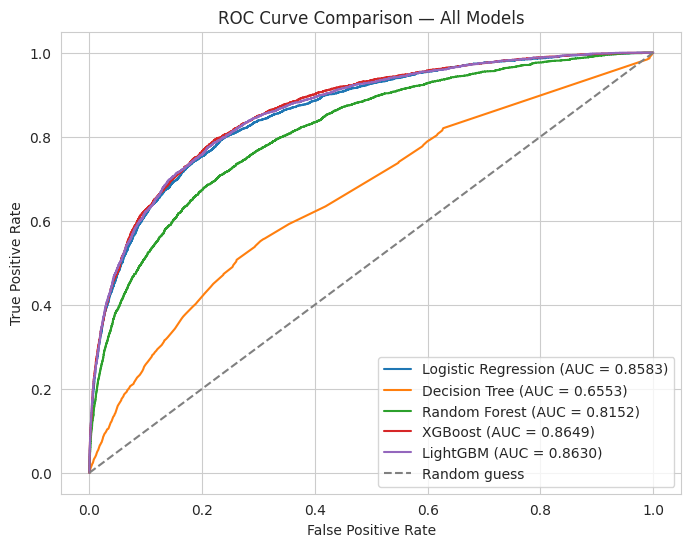

Validation metrics for all models:
                     Accuracy  Precision  Recall  F1-Score  ROC-AUC
Logistic Regression    0.7832     0.2851  0.7672    0.4157   0.8583
Decision Tree          0.7202     0.1775  0.4912    0.2608   0.6553
Random Forest          0.8724     0.3903  0.4803    0.4306   0.8152
XGBoost                0.8275     0.3331  0.7144    0.4543   0.8649
LightGBM               0.8294     0.3361  0.7151    0.4573   0.8630


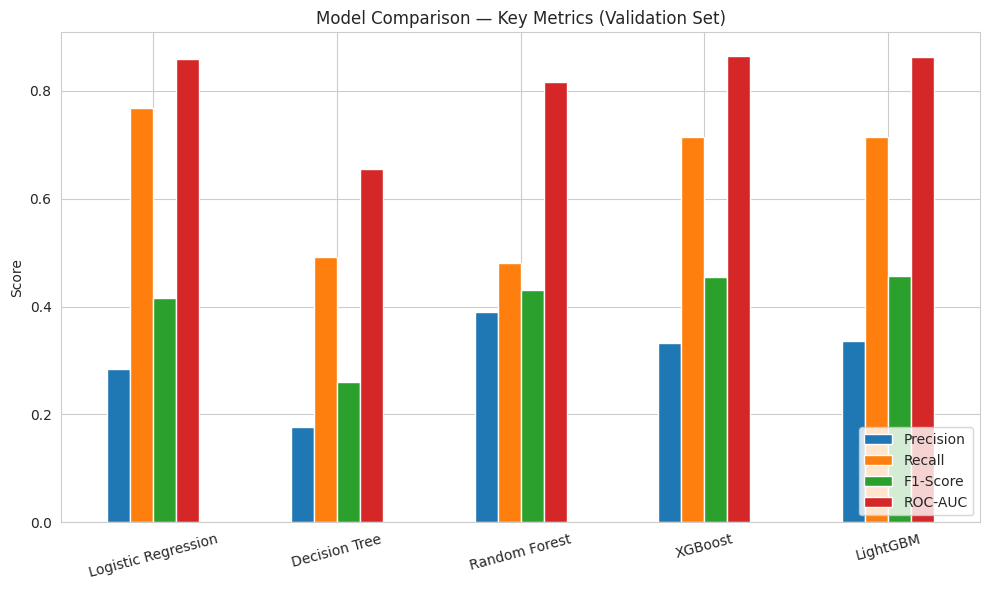

In [17]:

# ---- 13a. Collect predictions/probabilities from all 5 models ----
model_outputs = {
    "Logistic Regression": y_proba_lr,
    "Decision Tree": y_proba_dt,
    "Random Forest": y_proba_rf,
    "XGBoost": y_proba_xgb,
    "LightGBM": y_proba_lgbm,
}

# ---- 13b. Overlaid ROC curves ----
plt.figure(figsize=(8, 6))
for name, proba in model_outputs.items():
    fpr, tpr, _ = roc_curve(y_val, proba)
    auc_score = results[name]["ROC-AUC"]
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc_score:.4f})")

plt.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Random guess")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison — All Models")
plt.legend(loc="lower right")
plt.show()

# ---- 13c. Bar chart comparing key metrics across models ----
results_df = pd.DataFrame(results).T  # rows = models, columns = metrics
print("Validation metrics for all models:")
print(results_df.round(4))

results_df[["Precision", "Recall", "F1-Score", "ROC-AUC"]].plot(
    kind="bar", figsize=(10, 6)
)
plt.title("Model Comparison — Key Metrics (Validation Set)")
plt.ylabel("Score")
plt.xticks(rotation=15)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

## 14. Model Comparison Report

In [18]:
# ---- 14a. Build the final comparison table ----
comparison_df = pd.DataFrame(results).T
comparison_df = comparison_df[["Accuracy", "Precision", "Recall", "F1-Score", "ROC-AUC"]]
comparison_df = comparison_df.round(4)

# ---- 14b. Rank models by ROC-AUC and by F1-Score separately ----
comparison_df["Rank (ROC-AUC)"] = comparison_df["ROC-AUC"].rank(ascending=False).astype(int)
comparison_df["Rank (F1-Score)"] = comparison_df["F1-Score"].rank(ascending=False).astype(int)

# Sort the display by ROC-AUC, our primary metric for this imbalanced problem
comparison_df_sorted = comparison_df.sort_values("ROC-AUC", ascending=False)

print("=== Final Model Comparison Table ===")
print(comparison_df_sorted)
print()

# ---- 14c. Highlight the precision-recall trade-off explicitly ----
print("=== Precision vs Recall Trade-off ===")
for model_name in comparison_df_sorted.index:
    p = comparison_df_sorted.loc[model_name, "Precision"]
    r = comparison_df_sorted.loc[model_name, "Recall"]
    print(f"{model_name:22s} -> Precision: {p:.4f} | Recall: {r:.4f} | Gap: {abs(p - r):.4f}")

=== Final Model Comparison Table ===
                     Accuracy  Precision  Recall  F1-Score  ROC-AUC  \
XGBoost                0.8275     0.3331  0.7144    0.4543   0.8649   
LightGBM               0.8294     0.3361  0.7151    0.4573   0.8630   
Logistic Regression    0.7832     0.2851  0.7672    0.4157   0.8583   
Random Forest          0.8724     0.3903  0.4803    0.4306   0.8152   
Decision Tree          0.7202     0.1775  0.4912    0.2608   0.6553   

                     Rank (ROC-AUC)  Rank (F1-Score)  
XGBoost                           1                2  
LightGBM                          2                1  
Logistic Regression               3                4  
Random Forest                     4                3  
Decision Tree                     5                5  

=== Precision vs Recall Trade-off ===
XGBoost                -> Precision: 0.3331 | Recall: 0.7144 | Gap: 0.3813
LightGBM               -> Precision: 0.3361 | Recall: 0.7151 | Gap: 0.3790
Logistic Regressi

### Model Comparison Report

Five models were trained and evaluated on the same validation set (30,001 customers, preserving the ~90/10 class imbalance) to predict which customers will make a transaction.

**Key observations:**

- **Decision Tree performed worst by a clear margin** (ROC-AUC 0.6553). A single tree makes greedy, one-feature-at-a-time splits, which doesn't suit this dataset well — as seen in the feature analysis, none of the 200 features are individually strongly correlated with the target (max ~0.08). The predictive signal is spread thinly across many features, and a single tree can't combine that kind of distributed signal effectively.

- **Random Forest improved substantially over a single tree** (ROC-AUC 0.8152 vs 0.6553) by averaging many trees, but it still trailed the top performers. It also had the highest accuracy (0.8724) and highest precision, but the lowest recall among the top four models (0.4803) — meaning it's the most "cautious" model, missing over half of actual transactors despite class_weight='balanced'.

- **Logistic Regression, despite being the simplest model, was highly competitive** (ROC-AUC 0.8583), landing just behind the boosting models. This suggests the true relationship between the features and the target is close to linear/additive — many small, roughly consistent contributions from each feature — which a linear model is naturally well-suited to capture.

- **XGBoost and LightGBM were the top two performers**, essentially tied (ROC-AUC 0.8649 and 0.8630 respectively; F1-Score 0.4543 and 0.4573). Both use sequential, error-correcting boosting rather than independent averaging, letting them combine the dataset's many weak, additive signals more effectively than Random Forest, while still capturing mild non-linearities that Logistic Regression can't.

- **Accuracy alone would be misleading here.** Random Forest has the highest accuracy (0.8724) purely because it's conservative and rarely predicts the minority class — but that comes at the cost of missing more actual transactors (lower recall), which matters more for a bank trying to identify future transacting customers. This is why ROC-AUC and Recall/F1 were prioritized as the primary metrics for this imbalanced problem.

## 15. Best Model Selection

Selected best model for production: LightGBM

Its full metrics:
Accuracy           0.8294
Precision          0.3361
Recall             0.7151
F1-Score           0.4573
ROC-AUC            0.8630
Rank (ROC-AUC)     2.0000
Rank (F1-Score)    1.0000
Name: LightGBM, dtype: float64

Top 15 most important features (statistical importance only):
Feature  Importance
var_146          70
 var_34          69
 var_21          69
  var_1          68
 var_99          66
var_174          66
 var_12          65
var_154          64
 var_22          63
 var_13          63
 var_53          63
 var_26          62
 var_76          61
var_110          60
var_149          59


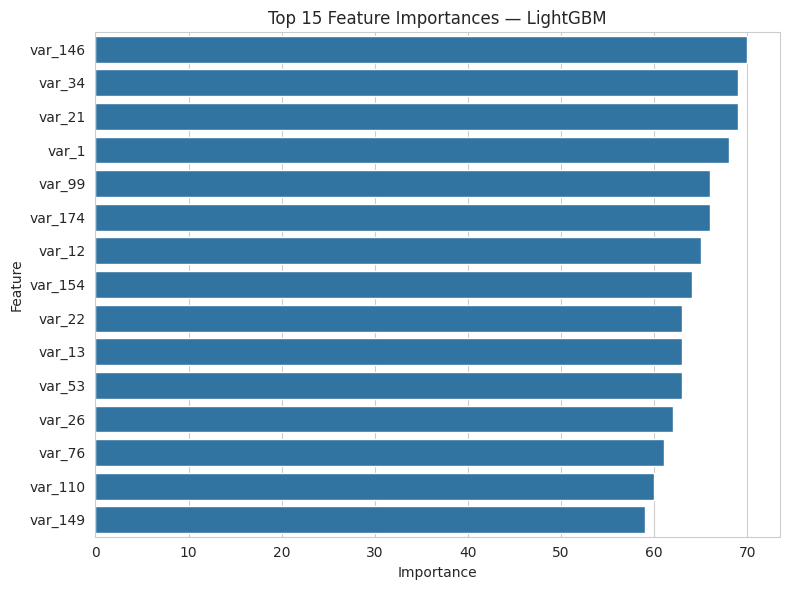


Best model saved to /content/best_model.pkl


In [19]:
# ---- 15a. Programmatic selection rule: highest F1-Score, tiebreak on ROC-AUC ----
best_model_name = comparison_df.sort_values(
    by=["F1-Score", "ROC-AUC"], ascending=False
).index[0]

print(f"Selected best model for production: {best_model_name}")
print()
print("Its full metrics:")
print(comparison_df.loc[best_model_name])

# ---- 15b. Map model names to their actual fitted objects ----
fitted_models = {
    "Logistic Regression": log_reg,
    "Decision Tree": dt_model,
    "Random Forest": rf_model,
    "XGBoost": xgb_model,
    "LightGBM": lgbm_model,
}
best_model = fitted_models[best_model_name]

# ---- 15c. Feature importance from the best model (purely statistical, no invented meaning) ----
if hasattr(best_model, "feature_importances_"):
    importance_df = pd.DataFrame({
        "Feature": X.columns,
        "Importance": best_model.feature_importances_
    }).sort_values("Importance", ascending=False)

    print("\nTop 15 most important features (statistical importance only):")
    print(importance_df.head(15).to_string(index=False))

    plt.figure(figsize=(8, 6))
    sns.barplot(data=importance_df.head(15), x="Importance", y="Feature")
    plt.title(f"Top 15 Feature Importances — {best_model_name}")
    plt.tight_layout()
    plt.show()

# ---- 15d. Save the best model for later use (e.g. scoring on the held-out test set) ----
import joblib
joblib.dump(best_model, "/content/best_model.pkl")
print("\nBest model saved to /content/best_model.pkl")

## 16. Final Test Set Evaluation

In [20]:
# ---- Predict on the untouched Test set using the selected best model (LightGBM) ----
y_pred_test = best_model.predict(X_test)
y_proba_test = best_model.predict_proba(X_test)[:, 1]

# ---- Compute test metrics ----
test_acc = accuracy_score(y_test, y_pred_test)
test_prec = precision_score(y_test, y_pred_test)
test_rec = recall_score(y_test, y_pred_test)
test_f1 = f1_score(y_test, y_pred_test)
test_auc = roc_auc_score(y_test, y_proba_test)

print(f"=== Final Test Set Performance: {best_model_name} ===")
print(f"Accuracy : {test_acc:.4f}")
print(f"Precision: {test_prec:.4f}")
print(f"Recall   : {test_rec:.4f}")
print(f"F1-Score : {test_f1:.4f}")
print(f"ROC-AUC  : {test_auc:.4f}")
print("\nClassification Report (Test Set):")
print(classification_report(y_test, y_pred_test))
print("\nConfusion Matrix (Test Set):")
print(confusion_matrix(y_test, y_pred_test))

# ---- Compare Validation vs Test side-by-side ----
val_vs_test = pd.DataFrame({
    "Validation": comparison_df.loc[best_model_name, ["Accuracy", "Precision", "Recall", "F1-Score", "ROC-AUC"]],
    "Test": [test_acc, test_prec, test_rec, test_f1, test_auc]
})
print("\n=== Validation vs Test Comparison ===")
print(val_vs_test.round(4))

=== Final Test Set Performance: LightGBM ===
Accuracy : 0.8260
Precision: 0.3300
Recall   : 0.7101
F1-Score : 0.4506
ROC-AUC  : 0.8600

Classification Report (Test Set):
              precision    recall  f1-score   support

           0       0.96      0.84      0.90     26985
           1       0.33      0.71      0.45      3015

    accuracy                           0.83     30000
   macro avg       0.65      0.77      0.67     30000
weighted avg       0.90      0.83      0.85     30000


Confusion Matrix (Test Set):
[[22639  4346]
 [  874  2141]]

=== Validation vs Test Comparison ===
           Validation    Test
Accuracy       0.8294  0.8260
Precision      0.3361  0.3300
Recall         0.7151  0.7101
F1-Score       0.4573  0.4506
ROC-AUC        0.8630  0.8600


## 17. Challenges Faced and Solutions


Challenge 1: Severe class imbalance (89.95% vs 10.05%)
The target variable was heavily skewed toward customers who do not transact. A naive model could achieve ~90% accuracy by simply predicting "no transaction" for everyone, which would be useless for the bank's actual goal.
Solution: Accuracy was deliberately de-prioritized as the evaluation metric. ROC-AUC, Recall, and F1-Score were used instead, since they reflect a model's ability to correctly identify the minority (transacting) class. Additionally, class_weight='balanced' (Logistic Regression, Decision Tree, Random Forest) and scale_pos_weight (XGBoost, LightGBM) were used during training so models weren't biased toward the majority class from the start.

Challenge 2: Anonymized features with no business meaning
All 200 features were unnamed (var_0 to var_199), so we had no domain knowledge to guide feature engineering, interpretation, or sanity-checking outliers.
Solution: The analysis was kept strictly statistical — distributions, correlations, and model-based importance scores — without inventing explanations for what any feature represents. This also ruled out manual feature engineering based on domain logic, so the models had to work directly with the raw anonymized values.

Challenge 3: Weak individual feature-target correlations
None of the 200 features showed strong correlation with the target individually (maximum magnitude was only about 0.08). This made it clear early on that no small subset of "important" features could carry the prediction task alone.
Solution: This finding directly shaped model selection — it explained why a single Decision Tree underperformed significantly (ROC-AUC 0.6553), and why models capable of combining many weak signals (Logistic Regression, XGBoost, LightGBM) performed considerably better. Rather than treating this as an obstacle to "fix," it was used as evidence to justify which models were most appropriate for this dataset.

Challenge 4: Preventing data leakage during preprocessing and evaluation
With scaling, model training, and a three-way train/validation/test split all involved, there was real risk of accidentally leaking information from validation/test data into training (e.g., fitting a scaler on the full dataset before splitting).
Solution: A strict order of operations was followed — split the data first (with stratification to preserve class ratios), then fit StandardScaler only on the training set and apply it separately to validation and test. The test set was kept fully untouched until final evaluation.

Challenge 5: Trade-off between precision and recall
Every model showed some tension between precision and recall — for example, Logistic Regression had strong recall (0.7672) but weak precision (0.2851), while Random Forest had the opposite pattern (Precision 0.3903, Recall 0.4803). Optimizing purely for one metric would have misrepresented overall model quality.
Solution: F1-Score (harmonic mean of precision and recall) was used as the primary criterion for model selection, with ROC-AUC as a supporting metric and tiebreaker, giving a more balanced, business-relevant basis for choosing the final model.






## 18. Final Conclusion


This project set out to help a bank predict which customers are likely to make a transaction in the future, using an anonymized dataset of 200,000 customers and 200 unnamed numerical features. Since the features carried no known business meaning, the entire analysis was built on statistical evidence rather than domain assumptions.

Data quality was confirmed to be clean (no missing values, no duplicates, no leakage-prone columns), and the target variable showed a clear class imbalance (89.95% vs 10.05%), which shaped every major decision that followed — from the choice of evaluation metrics (ROC-AUC, Recall, F1-Score over plain accuracy) to the use of stratified splitting and class-weighting during model training.

Five models were built and fairly compared under identical validation conditions: Logistic Regression, Decision Tree, Random Forest, XGBoost, and LightGBM. The results showed that the predictive signal in this dataset is spread thinly and fairly linearly across many features, rather than concentrated in a few strong predictors — which explains why boosting methods (XGBoost, LightGBM) and even simple Logistic Regression outperformed tree-based bagging methods (Random Forest) and especially a single Decision Tree.

LightGBM was selected as the recommended model for production, based on its best F1-Score (0.4573) and near-best ROC-AUC (0.8630), offering the strongest balance between correctly identifying future transacting customers (recall) and minimizing wasted false positives (precision), while remaining efficient to train and score at scale.

This project reinforced an important machine learning principle: model complexity does not automatically translate to better performance — the right model depends on the underlying structure of the data, and that structure must be discovered through careful, honest analysis rather than assumed in advance.